# VIS4AI Phase II: Evaluating YOLO26n Learned Representations (Hypothesis H2-C)

**Hypothesis (H2-C):** *Systematic misclassifications between visually similar PASCAL VOC classes (e.g., `dog`/`cat`, `cow`/`horse`/`sheep`, or `chair`/`sofa`) arise because their learned representations overlap in the penultimate neck layer, and the model relies on shared coarse silhouette/texture cues (like fur or four-legged posture) rather than class-discriminative parts (ears, snout, hooves).*

1. **Setup, Hooks & VOC2007 RoI Feature Extraction:** Hooks `backbone_p3 (L4)` and the penultimate neck layers (`L16`, `L19`, `L22`), parses `VOC2007/Annotations`, matches predictions, and pools per-channel representations inside ground-truth bounding boxes.
2. **High-Dimensional Representation Overlap & Projection Space (*ChannelExplorer* / *Steinparz et al.*):**
   - **Exact High-D Geometry:** Pairwise Cosine Similarity & Top-20% Active Channel Jaccard Similarity Heatmaps (avoiding dimensionality-reduction distortion) plus High-D Cosine Centroid Margin boxplots.
   - **2D UMAP Projection + High-D K-Means Clustering:** Scatter plots and cluster mixing bars showing learned inter-class ambiguity.
3. **Class-to-Neuron Activation Matrix & Cross-Layer Comparison (*Alsallakh et al.*):**
   - Compares `backbone_p3 (L4)` against the penultimate neck layer (`L19` / `L22`) sorted by semantic super-group.

## 1. Setup, Forward Hooks & VOC2007 Object-Level Feature Extraction

In [1]:
from pathlib import Path
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, normalized_mutual_info_score
from sklearn.metrics.pairwise import cosine_similarity
import umap
from ultralytics import YOLO

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# ==========================================
# PATHS & CONFIGURATION
# ==========================================
CONF_THRESHOLD = 0.15
IOU_THRESHOLD = 0.50
MAX_IMAGES = None  # Set to e.g. 500 for fast testing, or None to run all VOC2007 images

base_dir = Path(r"C:\Users\andru\Desktop\Semester3\ai_visua")
voc_dir = Path(r"C:\Users\andru\Downloads\VOC_dataset\VOCdevkit\VOC2007")
model = YOLO(base_dir / "yolo26n.pt")

VOC_TO_COCO_ID = {
    "aeroplane": 4,
    "bicycle": 1,
    "bird": 14,
    "boat": 8,
    "bottle": 39,
    "bus": 5,
    "car": 2,
    "cat": 15,
    "chair": 56,
    "cow": 19,
    "diningtable": 60,
    "dog": 16,
    "horse": 17,
    "motorbike": 3,
    "person": 0,
    "pottedplant": 58,
    "sheep": 18,
    "sofa": 57,
    "train": 6,
    "tvmonitor": 62,
}
COCO_ID_TO_VOC = {v: k for k, v in VOC_TO_COCO_ID.items()}

# Hypothesis H2-C Target Semantic Confusion Groups
CONFUSION_GROUPS = {
    "Pets (dog/cat)": ["dog", "cat"],
    "Livestock (cow/horse/sheep)": ["cow", "horse", "sheep"],
    "Seating (chair/sofa)": ["chair", "sofa"],
}
ALL_TARGET_CLASSES = [c for grp in CONFUSION_GROUPS.values() for c in grp]

def get_confusion_group(cls_name):
    for grp_name, members in CONFUSION_GROUPS.items():
        if cls_name in members:
            return grp_name
    return "Other"

print("Weights found:", (base_dir / "yolo26n.pt").exists())
print("Target H2-C classes:", ALL_TARGET_CLASSES)

Weights found: True
Target H2-C classes: ['dog', 'cat', 'cow', 'horse', 'sheep', 'chair', 'sofa']


In [2]:
# Register hooks on backbone_p3 (L4) and penultimate neck layers (P3, P4, P5)
detect_head = model.model.model[-1]
neck_indices = list(detect_head.f) if hasattr(detect_head, "f") else [16, 19, 22]

layers = {
    "backbone_p3 (L4)": 4,
    f"neck_p3 (L{neck_indices[0]})": neck_indices[0],
    f"neck_p4 (L{neck_indices[1]})": neck_indices[1],
    f"neck_p5 (L{neck_indices[2]})": neck_indices[2],
}
NECK_KEYS = [
    f"neck_p3 (L{neck_indices[0]})",
    f"neck_p4 (L{neck_indices[1]})",
    f"neck_p5 (L{neck_indices[2]})",
]
EARLY_KEY = "backbone_p3 (L4)"

acts = {}
hooks = []
for name, idx in layers.items():
    h = model.model.model[idx].register_forward_hook(
        lambda m, i, o, layer_name=name: acts.update({layer_name: (o[0] if isinstance(o, (tuple, list)) else o).detach().cpu()})
    )
    hooks.append(h)

def get_gt_objects(xml_path):
    root = ET.parse(xml_path).getroot()
    objs = []
    for obj in root.findall("object"):
        diff_tag = obj.find("difficult")
        if diff_tag is not None and int(diff_tag.text) == 1:
            continue
        name = obj.find("name").text.strip().lower()
        if name not in VOC_TO_COCO_ID:
            continue
        b = obj.find("bndbox")
        box = [
            float(b.find("xmin").text),
            float(b.find("ymin").text),
            float(b.find("xmax").text),
            float(b.find("ymax").text),
        ]
        if (box[2] - box[0]) > 4 and (box[3] - box[1]) > 4:
            objs.append((name, box))
    return objs

def calc_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_of_box_1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area_of_box_2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    return inter / (area_of_box_1 + area_of_box_2 - inter + 1e-8)

def get_box_channel_vector(feat_map, box, img_w, img_h):
    _, C, h, w = feat_map.shape
    x1 = max(0, int(box[0] * w / img_w))
    y1 = max(0, int(box[1] * h / img_h))
    x2 = min(w, max(x1 + 1, int(np.ceil(box[2] * w / img_w))))
    y2 = min(h, max(y1 + 1, int(np.ceil(box[3] * h / img_h))))
    roi = feat_map[0, :, y1:y2, x1:x2]
    vec = 0.5 * (roi.mean(dim=(1, 2)) + roi.amax(dim=(1, 2)))
    return vec.numpy()

img_files = sorted((voc_dir / "JPEGImages").glob("*.jpg"))
if MAX_IMAGES is not None:
    img_files = img_files[:MAX_IMAGES]

records = []
layer_vectors = {name: [] for name in layers}

for img_path in tqdm(img_files, desc="Extracting YOLO26n Features on VOC2007"):
    xml_path = voc_dir / "Annotations" / f"{img_path.stem}.xml"
    if not xml_path.exists():
        continue
    gt_objs = get_gt_objects(xml_path)
    if not gt_objs:
        continue

    img_w, img_h = Image.open(img_path).size

    acts.clear()
    res = model.predict(img_path, conf=CONF_THRESHOLD, verbose=False)[0]
    pred_boxes = res.boxes.xyxy.cpu().numpy() if res.boxes is not None else np.empty((0, 4))
    pred_classes = res.boxes.cls.cpu().numpy().astype(int) if res.boxes is not None else np.empty((0,), dtype=int)
    pred_confs = res.boxes.conf.cpu().numpy() if res.boxes is not None else np.empty((0,))

    for cls_name, gt_box in gt_objs:
        gt_group = get_confusion_group(cls_name)

        best_iou = 0.0
        best_pred_cls = "NONE"
        best_pred_conf = 0.0
        for p_box, p_cid, p_conf in zip(pred_boxes, pred_classes, pred_confs):
            if p_cid not in COCO_ID_TO_VOC:
                continue
            iou = calc_iou(gt_box, p_box)
            if iou >= IOU_THRESHOLD and iou > best_iou:
                best_iou = iou
                best_pred_cls = COCO_ID_TO_VOC[p_cid]
                best_pred_conf = float(p_conf)

        if best_pred_cls == "NONE":
            outcome = "FN"
        elif best_pred_cls == cls_name:
            outcome = "TP"
        elif gt_group != "Other" and best_pred_cls in CONFUSION_GROUPS[gt_group]:
            outcome = "Misclassified_Within_Group"
        else:
            outcome = "Misclassified_Other"

        for name in layers:
            vec = get_box_channel_vector(acts[name], gt_box, img_w, img_h)
            layer_vectors[name].append(vec)

        records.append({
            "obj_id": len(records),
            "img_path": str(img_path),
            "gt_cls": cls_name,
            "gt_group": gt_group,
            "pred_cls": best_pred_cls,
            "pred_conf": best_pred_conf,
            "iou": best_iou,
            "outcome": outcome,
        })

# Clean up hooks after feature extraction
for h in hooks:
    h.remove()

df_objs = pd.DataFrame(records)
for name in layers:
    layer_vectors[name] = np.array(layer_vectors[name])

print(f"\nTotal extracted VOC2007 objects: {len(df_objs)}")
print(df_objs[df_objs["gt_group"] != "Other"].groupby(["gt_group", "gt_cls", "outcome"]).size().unstack(fill_value=0))

Extracting YOLO26n Features on VOC2007:   0%|          | 0/9963 [00:00<?, ?it/s]


Total extracted VOC2007 objects: 24640
outcome                              FN  Misclassified_Other  \
gt_group                    gt_cls                             
Livestock (cow/horse/sheep) cow      19                   11   
                            horse    29                   12   
                            sheep    41                   17   
Pets (dog/cat)              cat      41                   15   
                            dog      62                   84   
Seating (chair/sofa)        chair   188                   48   
                            sofa     46                    6   

outcome                             Misclassified_Within_Group    TP  
gt_group                    gt_cls                                    
Livestock (cow/horse/sheep) cow                             20   453  
                            horse                           14   655  
                            sheep                            7   434  
Pets (dog/cat)              

## 2. High-Dimensional Representation Overlap & Projection Space (*ChannelExplorer* / *Steinparz et al.*)
- **Exact High-D Geometry:** Pairwise Cosine Similarity & Top-20% Active Channel Jaccard Similarity Heatmaps (avoiding dimensionality-reduction distortion) plus High-D Cosine Centroid Margin boxplots.
- **2D UMAP Projection + High-D K-Means Clustering:** Scatter plots and cluster mixing bars showing learned inter-class ambiguity.

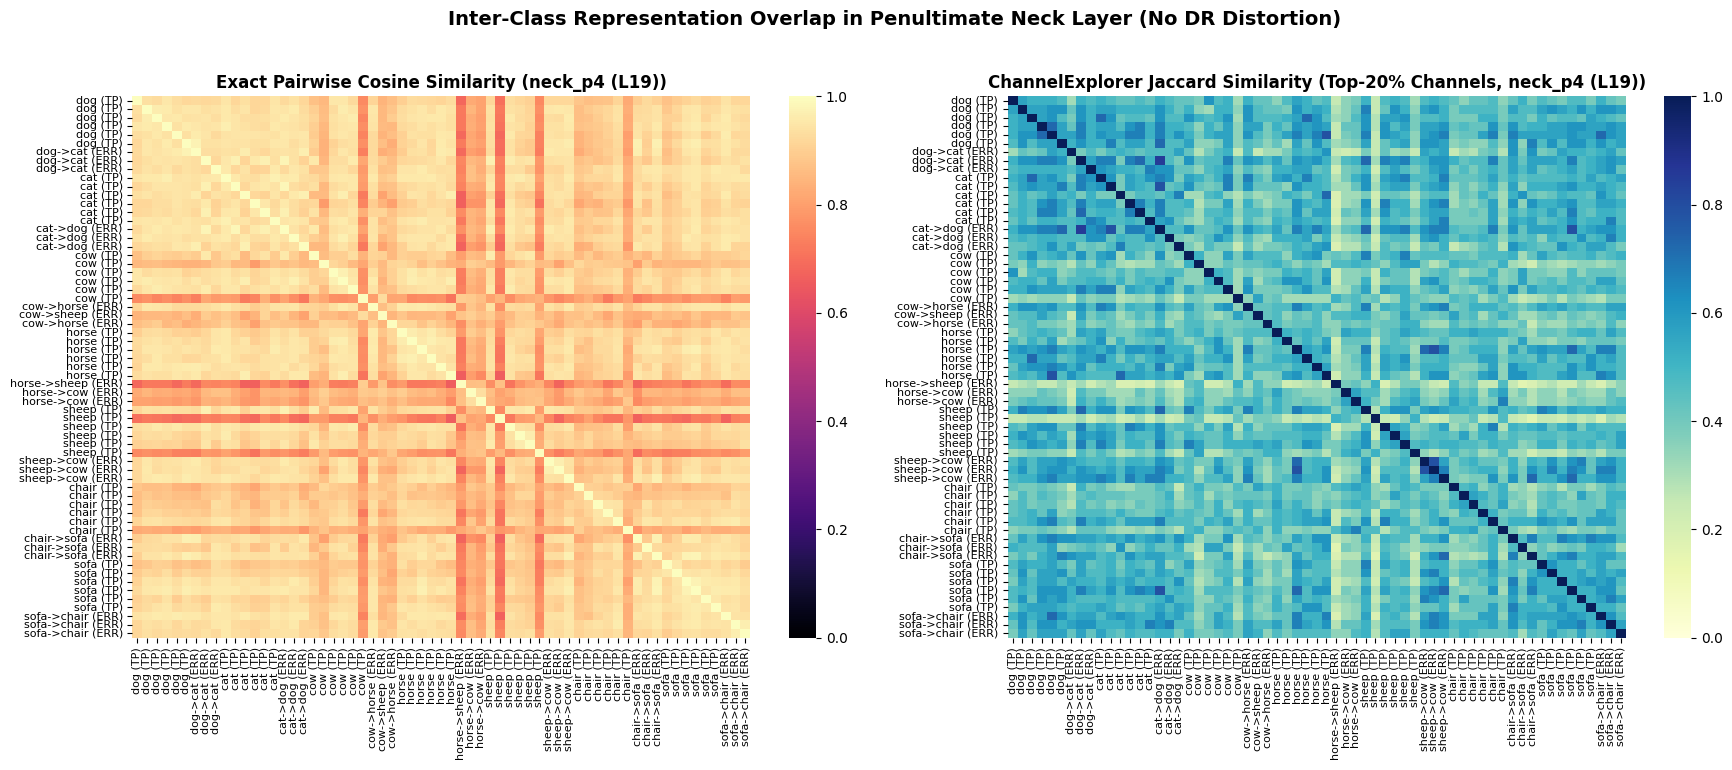

In [3]:
# Select penultimate semantic neck layer: NECK_KEYS[1] is neck_p4 (L19), NECK_KEYS[2] is neck_p5 (L22)
SEMANTIC_LAYER = NECK_KEYS[1]
Z_neck = layer_vectors[SEMANTIC_LAYER]
Z_norm = Z_neck / (np.linalg.norm(Z_neck, axis=1, keepdims=True) + 1e-8)

def compute_jaccard_activation_matrix(vectors, top_k_ratio=0.20):
    k = max(1, int(vectors.shape[1] * top_k_ratio))
    thresh = np.partition(vectors, -k, axis=1)[:, -k][:, None]
    active = (vectors >= thresh).astype(np.float32)
    intersection = active @ active.T
    row_sums = active.sum(axis=1, keepdims=True)
    union = row_sums + row_sums.T - intersection
    return intersection / (union + 1e-8)

rep_indices = []
rep_labels = []
SAMPLES_PER_BUCKET = 6

for cls_name in ALL_TARGET_CLASSES:
    tp_ids = df_objs[(df_objs["gt_cls"] == cls_name) & (df_objs["outcome"] == "TP")].index.tolist()
    mis_ids = df_objs[(df_objs["gt_cls"] == cls_name) & (df_objs["outcome"] == "Misclassified_Within_Group")].index.tolist()
    for idx in tp_ids[:SAMPLES_PER_BUCKET]:
        rep_indices.append(idx)
        rep_labels.append(f"{cls_name} (TP)")
    for idx in mis_ids[:min(3, SAMPLES_PER_BUCKET)]:
        pred_c = df_objs.loc[idx, "pred_cls"]
        rep_indices.append(idx)
        rep_labels.append(f"{cls_name}->{pred_c} (ERR)")

cos_mat = cosine_similarity(Z_norm[rep_indices])
jac_mat = compute_jaccard_activation_matrix(Z_neck[rep_indices], top_k_ratio=0.20)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
sns.heatmap(cos_mat, xticklabels=rep_labels, yticklabels=rep_labels, cmap="magma", vmin=0.0, vmax=1.0, ax=axes[0])
axes[0].set_title(f"Exact Pairwise Cosine Similarity ({SEMANTIC_LAYER})", fontsize=12, fontweight="bold")
axes[0].tick_params(axis="x", rotation=90, labelsize=8)
axes[0].tick_params(axis="y", labelsize=8)

sns.heatmap(jac_mat, xticklabels=rep_labels, yticklabels=rep_labels, cmap="YlGnBu", vmin=0.0, vmax=1.0, ax=axes[1])
axes[1].set_title(f"ChannelExplorer Jaccard Similarity (Top-20% Channels, {SEMANTIC_LAYER})", fontsize=12, fontweight="bold")
axes[1].tick_params(axis="x", rotation=90, labelsize=8)
axes[1].tick_params(axis="y", labelsize=8)

plt.suptitle("Inter-Class Representation Overlap in Penultimate Neck Layer (No DR Distortion)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

--- Cosine Similarity Between Learned Class Centroids (neck_p4 (L19)) ---


,dog,cat,cow,horse,sheep,chair,sofa
dog,1.000,0.995,0.968,0.989,0.953,0.964,0.983
cat,0.995,1.000,0.950,0.982,0.933,0.950,0.979
cow,0.968,0.950,1.000,0.970,0.986,0.970,0.956
horse,0.989,0.982,0.970,1.000,0.956,0.972,0.980
sheep,0.953,0.933,0.986,0.956,1.000,0.963,0.941
chair,0.964,0.950,0.970,0.972,0.963,1.000,0.974
sofa,0.983,0.979,0.956,0.980,0.941,0.974,1.000


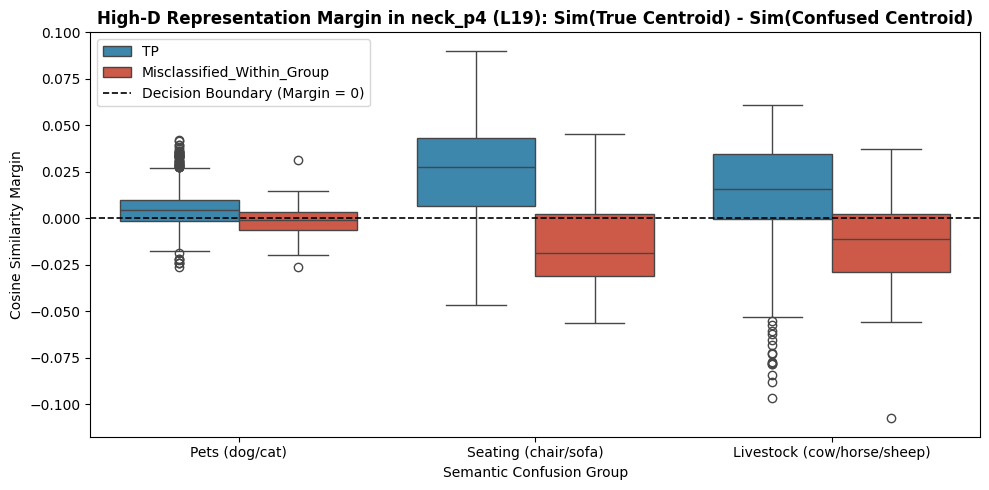

In [4]:
# High-D Cosine Centroid Margin Boxplots
class_centroids = {}
for cls_name in ALL_TARGET_CLASSES:
    tp_mask = (df_objs["gt_cls"] == cls_name) & (df_objs["outcome"] == "TP")
    if tp_mask.sum() > 0:
        c_vec = Z_norm[tp_mask].mean(axis=0)
        class_centroids[cls_name] = c_vec / (np.linalg.norm(c_vec) + 1e-8)

centroid_df = pd.DataFrame(
    {c1: {c2: float(np.dot(class_centroids[c1], class_centroids[c2])) for c2 in class_centroids} for c1 in class_centroids}
)
print(f"--- Cosine Similarity Between Learned Class Centroids ({SEMANTIC_LAYER}) ---")
display(centroid_df.round(3))

margin_rows = []
for idx, row in df_objs[df_objs["gt_cls"].isin(ALL_TARGET_CLASSES)].iterrows():
    if row["outcome"] not in ["TP", "Misclassified_Within_Group"]:
        continue
    gt = row["gt_cls"]
    grp_peers = [c for c in CONFUSION_GROUPS[row["gt_group"]] if c != gt and c in class_centroids]
    if not grp_peers or gt not in class_centroids:
        continue
    z = Z_norm[idx]
    sim_true = float(np.dot(z, class_centroids[gt]))
    sim_other = max(float(np.dot(z, class_centroids[p])) for p in grp_peers)
    margin_rows.append({
        "gt_group": row["gt_group"],
        "gt_cls": gt,
        "outcome": row["outcome"],
        "representation_margin": sim_true - sim_other
    })

df_margins = pd.DataFrame(margin_rows)
if not df_margins.empty:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_margins, x="gt_group", y="representation_margin", hue="outcome", palette={"TP": "#2b8cbe", "Misclassified_Within_Group": "#e34a33"})
    plt.axhline(0.0, color="black", linestyle="--", linewidth=1.2, label="Decision Boundary (Margin = 0)")
    plt.title(f"High-D Representation Margin in {SEMANTIC_LAYER}: Sim(True Centroid) - Sim(Confused Centroid)", fontsize=12, fontweight="bold")
    plt.ylabel("Cosine Similarity Margin")
    plt.xlabel("Semantic Confusion Group")
    plt.legend()
    plt.tight_layout()
    plt.show()

High-D Neck Space Metrics (neck_p4 (L19)) -> Cosine Silhouette: -0.025 | GT vs. K-Means NMI: 0.281


gt_cls,cat,chair,cow,dog,horse,sheep,sofa
hd_cluster,,,,,,,
0,48,177,21,98,87,4,319
1,8,6,129,21,25,163,0
2,5,357,28,15,21,14,8
3,1,597,4,8,67,1,40
4,94,78,111,201,329,65,14
5,474,53,37,395,91,43,31
6,48,50,143,115,49,151,23


C:\Users\andru\AppData\Roaming\Python\Python311\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\andru\AppData\Roaming\Python\Python311\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


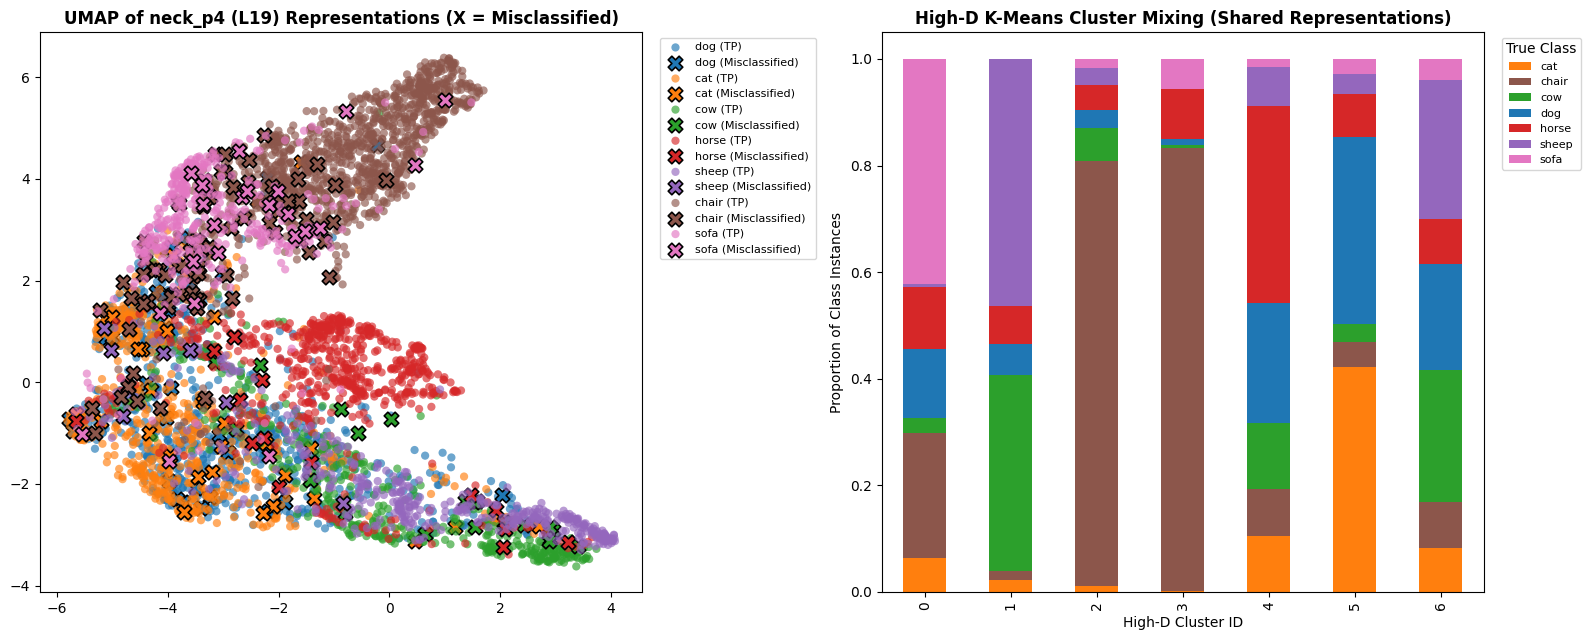

In [5]:
# 2D UMAP Projection + High-D K-Means Clustering
sub_df = df_objs[(df_objs["gt_cls"].isin(ALL_TARGET_CLASSES)) & (df_objs["outcome"].isin(["TP", "Misclassified_Within_Group"]))].copy()
sub_Z = Z_norm[sub_df.index.values]

kmeans_hd = KMeans(n_clusters=len(ALL_TARGET_CLASSES), random_state=SEED, n_init=10)
sub_df["hd_cluster"] = kmeans_hd.fit_predict(sub_Z)

nmi = normalized_mutual_info_score(sub_df["gt_cls"], sub_df["hd_cluster"])
sil = silhouette_score(sub_Z, sub_df["gt_cls"], metric="cosine")
print(f"High-D Neck Space Metrics ({SEMANTIC_LAYER}) -> Cosine Silhouette: {sil:.3f} | GT vs. K-Means NMI: {nmi:.3f}")

cluster_comp = pd.crosstab(sub_df["hd_cluster"], sub_df["gt_cls"])
display(cluster_comp)

reducer = umap.UMAP(n_neighbors=20, min_dist=0.15, metric="cosine", random_state=SEED)
coords_2d = reducer.fit_transform(sub_Z)
sub_df["umap_x"] = coords_2d[:, 0]
sub_df["umap_y"] = coords_2d[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
palette = sns.color_palette("tab10", len(ALL_TARGET_CLASSES))
cls_color_map = dict(zip(ALL_TARGET_CLASSES, palette))

for cls_name in ALL_TARGET_CLASSES:
    tp_sub = sub_df[(sub_df["gt_cls"] == cls_name) & (sub_df["outcome"] == "TP")]
    err_sub = sub_df[(sub_df["gt_cls"] == cls_name) & (sub_df["outcome"] == "Misclassified_Within_Group")]
    axes[0].scatter(tp_sub["umap_x"], tp_sub["umap_y"], c=[cls_color_map[cls_name]], label=f"{cls_name} (TP)", alpha=0.65, s=35, edgecolors="none")
    if len(err_sub) > 0:
        axes[0].scatter(err_sub["umap_x"], err_sub["umap_y"], c=[cls_color_map[cls_name]], marker="X", s=110, edgecolors="black", linewidths=1.2, label=f"{cls_name} (Misclassified)")

axes[0].set_title(f"UMAP of {SEMANTIC_LAYER} Representations (X = Misclassified)", fontsize=12, fontweight="bold")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

cluster_comp_norm = cluster_comp.div(cluster_comp.sum(axis=1), axis=0)
cluster_comp_norm.plot(kind="bar", stacked=True, color=[cls_color_map[c] for c in cluster_comp_norm.columns], ax=axes[1])
axes[1].set_title("High-D K-Means Cluster Mixing (Shared Representations)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("High-D Cluster ID")
axes[1].set_ylabel("Proportion of Class Instances")
axes[1].legend(title="True Class", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

## 3. Class-to-Neuron Activation Matrix & Cross-Layer Comparison (*Alsallakh et al.*)
- Compares `backbone_p3 (L4)` against the penultimate neck layer (`L19` / `L22`) sorted by semantic super-group.

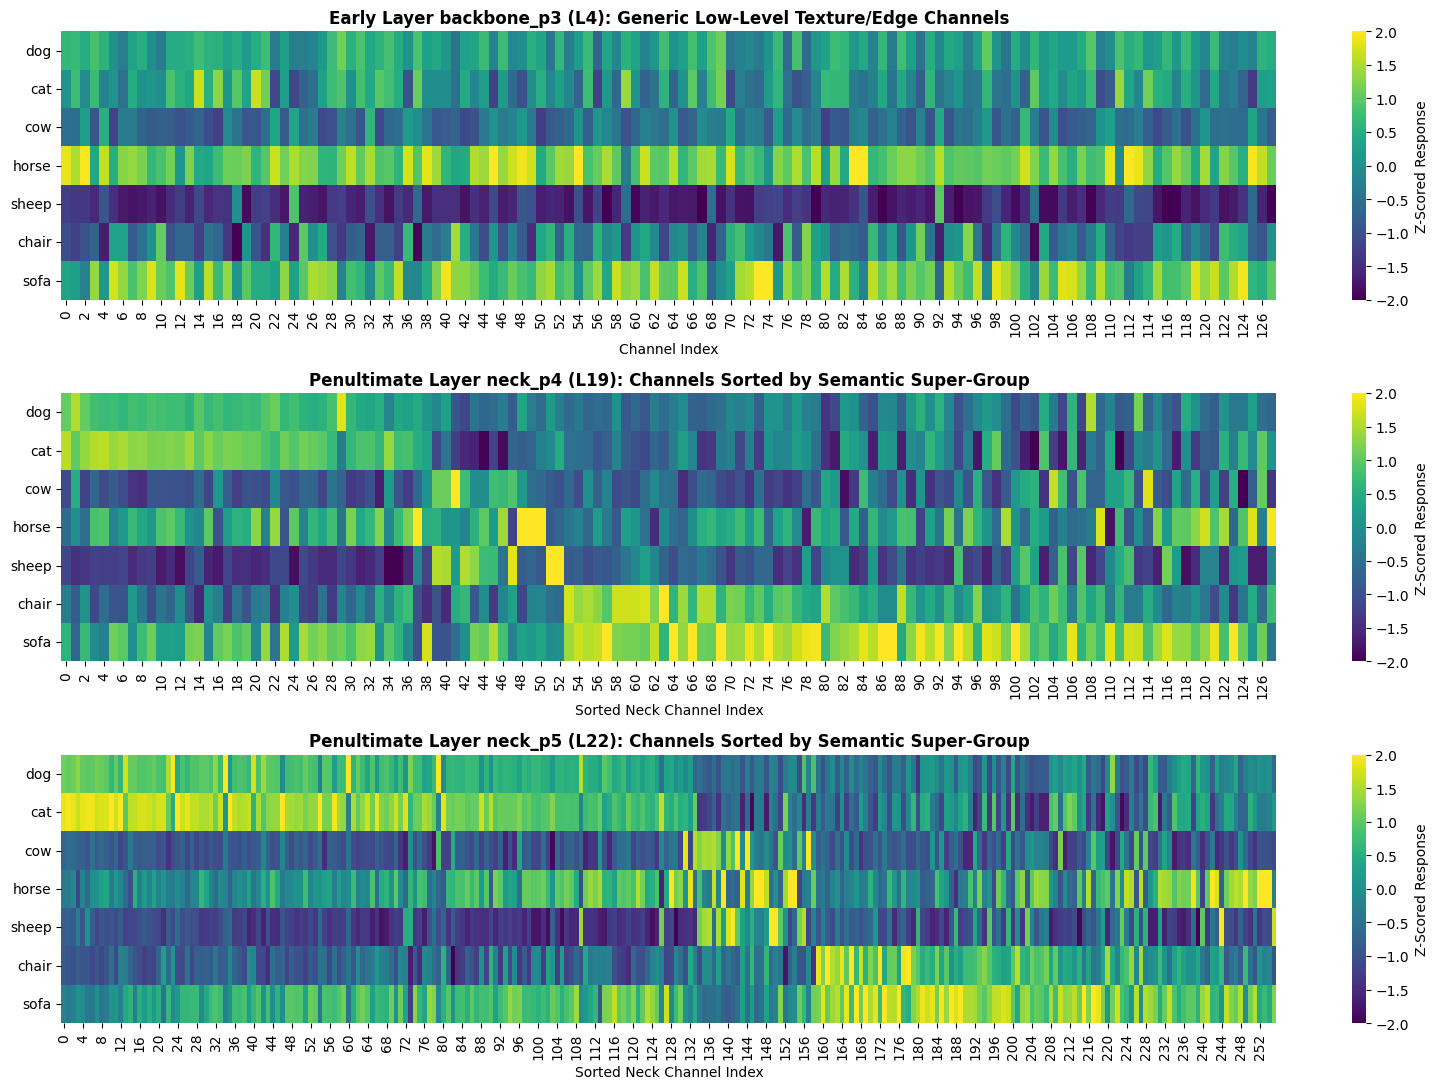

In [6]:
def build_class_channel_matrix(df, vectors, classes):
    mat = []
    for c in classes:
        idx = df[df["gt_cls"] == c].index.values
        mat.append(vectors[idx].mean(axis=0))
    mat = np.array(mat)
    mat_norm = (mat - mat.mean(axis=0, keepdims=True)) / (mat.std(axis=0, keepdims=True) + 1e-8)
    return mat, mat_norm

def sort_channels_by_supergroup(z_mat):
    group_means = []
    for grp_name, members in CONFUSION_GROUPS.items():
        m_indices = [ALL_TARGET_CLASSES.index(m) for m in members]
        group_means.append(z_mat[m_indices].mean(axis=0))
    group_means = np.array(group_means)
    dominant_grp = np.argmax(group_means, axis=0)
    strength = np.max(group_means, axis=0)
    return np.lexsort((-strength, dominant_grp))

_, early_z = build_class_channel_matrix(df_objs, layer_vectors[EARLY_KEY], ALL_TARGET_CLASSES)
_, neck_p4_z = build_class_channel_matrix(df_objs, layer_vectors[NECK_KEYS[1]], ALL_TARGET_CLASSES)
_, neck_p5_z = build_class_channel_matrix(df_objs, layer_vectors[NECK_KEYS[2]], ALL_TARGET_CLASSES)

fig, axes = plt.subplots(3, 1, figsize=(16, 11))

sns.heatmap(early_z, yticklabels=ALL_TARGET_CLASSES, cmap="viridis", vmin=-2, vmax=2, cbar_kws={"label": "Z-Scored Response"}, ax=axes[0])
axes[0].set_title(f"Early Layer {EARLY_KEY}: Generic Low-Level Texture/Edge Channels", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Channel Index")

sns.heatmap(neck_p4_z[:, sort_channels_by_supergroup(neck_p4_z)], yticklabels=ALL_TARGET_CLASSES, cmap="viridis", vmin=-2, vmax=2, cbar_kws={"label": "Z-Scored Response"}, ax=axes[1])
axes[1].set_title(f"Penultimate Layer {NECK_KEYS[1]}: Channels Sorted by Semantic Super-Group", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Sorted Neck Channel Index")

sns.heatmap(neck_p5_z[:, sort_channels_by_supergroup(neck_p5_z)], yticklabels=ALL_TARGET_CLASSES, cmap="viridis", vmin=-2, vmax=2, cbar_kws={"label": "Z-Scored Response"}, ax=axes[2])
axes[2].set_title(f"Penultimate Layer {NECK_KEYS[2]}: Channels Sorted by Semantic Super-Group", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Sorted Neck Channel Index")

plt.tight_layout()
plt.show()